## Problem Metadata 
DO NOT DELETE (JSON Block; the metadata and course context MUST be in the first cell)

```json
{
    "problem_title": "pistonCylinderExergyClosedSystem",
    "author": "cuhail",
    "year": "Fa26",
    "difficulty_tags": ["medium"],
    "topic": "Exergy",
    "lecture_reference": {
        "lecture_id": "",
        "subtopics": [
            {
              "key": "Fa25-L7c-3.0",
              "title": "Multisage Compressor With Cooling",
            }
        ]
    },
    "book_reference": {
        "chapter_number": 8,
        "title": "Exergy",
        "sections": [
            "Closed system exergy analysis",
            "Piston Cylinder",
        ]
    },
    "notes": ""
}
```

## 1. Problem Statement
Problem 8-34 from Cengels Thermodynamics 9th Edition

A piston-cylinder device contains 8 kg of refrigerant-134a at 0.7 MPa and 60°C. The refrigerant is now cooled at constant pressure until it exists as a liquid at 20°C. If the surroundings are at 100 kPa and 20°C.

**Goal:**
- determine the exergy of the refrigerant at the initial and the final states.
- determine the exergy destroyed during the process. 


## 2. Schematic
Draw a cylinder piston device filled with refrigerant undergoing a process from the initial state 1 to state 2. The piston is freely movable between process 1 and 2. No mass is transferred with the environment during the process. Heat is transferred with the environment during the process. 

## 3. Assumptions and Approximations
* **System** The refrigerant and the piston is used as the system of interest.
* **Closed System** no mass crosses the boundary.
* Neglect changes in kinetic and potential energy ($\Delta KE\approx0$, $\Delta PE\approx0$). (Justification: The velocities are typically low, or the change in height is negligible compared to the enthalpy change.)
* **Incompressible fluid** assume the refrigerant in its liquid form can be decribed as an incompressible fluid.
* **Irreversible process**: assume the process is irreversible since there is no mention of reversiblity in the problem. 
* **Isobaric**: Cooling from state 1 to 2 occurs at constant pressure.
* **Non-adiabatic**: Heat transfer occurs between the system and the environment.
* **Properties** We will use pyCalor to determine properties.


## 4. Physical Laws and Governing Equations
1. **Exergy of a stationary fluid**
$$\phi = u - u_0 +p_0 (v-v_0)-T_0 (s-s_0) +\frac{V^2}{2} +gz$$

2. **Exergy destruction**
$$X_{destroyed} = T_0 S_{gen}= T_0 (S_2 - S_1) - \frac{Q_{12}}/{T_0}$$

3.  **First Law of Thermodynamics (Energy Balance for a Closed System):**
$$\Delta E_\text{system} = E_\text{in} - E_\text{out} = (W_\text{in} + Q_\text{in}) - (W_\text{out} + Q_\text{out})$$

4.  **Conservation of Mass (Mass Balance for a Closed System):**
$$\Delta m_\text{CV} = 0$$

By definition we can write that the changes in the energy of the system only depend on changes in internal energy, kinetic energy, and potential energy. 

$$\Delta E_\text{system} = \Delta U + \Delta KE + \Delta PE $$

Neglect kinetic and potential energy changes:

$$\Delta E_\text{system} = \Delta U $$

$$\Delta U = U_2 - U_1 = (Q_\text{in} - Q_\text{out}) + (W_\text{in} - W_\text{out}) $$

5. **Constant pressure work** 
$$W_{12} = p_0 (V_2 - V_1) $$

We can then write:

$$X_{destroyed} = T_0 S_{gen}= T_0 (S_2 - S_1) - \frac{U_2-U_1-p_0 (V_2 - V_1)}{T_0}$$



In [1]:
## 5. Properties (Code Cell)
!pip install pyCalor
from pyCalor import thermo as th

substance = 'air'
mdot_kgPerS = 0.15

# Properties
p1_Pa = 100e3
T1_C = 27
T1_K = T1_C +273.15

pressureRatio = 2.5

p2_Pa = p1_Pa * pressureRatio

p3_Pa = p2_Pa
T3_C = 27
T3_K = T3_C + 273.15

p4_Pa = p3_Pa * pressureRatio

# state 1
st1 = th.state(substance,T=(T1_C,'C'),p=(p1_Pa,'Pa'),name='1')
h1_JperKg = st1.h*1e3
s1_JperKgperK = st1.s*1e3

# state 2
s2_JperKgperK = s1_JperKgperK
st2 = th.state(substance,s=(s2_JperKgperK,'J/kg K'),p=(p2_Pa,'Pa'),name='2')
h2_JperKg = st2.h*1e3
T2_K = st2.T

# state 3
st3 = th.state(substance,T=(T3_C,'C'),p=(p3_Pa,'Pa'),name='3')
h3_JperKg = st3.h*1e3
s3_JperKgperK = st3.s*1e3

# state 4
s4_JperKgperK = s3_JperKgperK
st4 = th.state(substance,s=(s4_JperKgperK,'J/kg K'),p=(p4_Pa,'Pa'),name='4')
h4_JperKg = st4.h*1e3
T4_K = st4.T

# process
pr = th.process([(st1,st2),(st2,st3),(st3,st4)])

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.5/6.5 MB 58.4 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.7/5.7 MB 81.7 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [pyCalor]m2/4 [CoolProp]


(a) Wdot_kW = 27.1 kW.
(b) Wdot_kW = 31.1 kW.


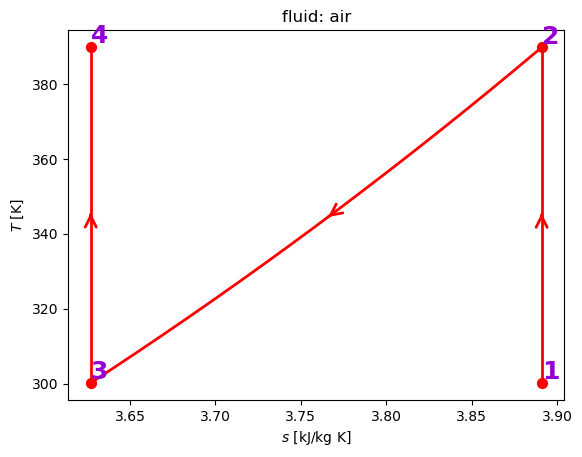

In [2]:
# 6 Calculations (Code Cell)
# Work in
Wdot_W = mdot_kgPerS*((h2_JperKg - h1_JperKg)+(h4_JperKg - h3_JperKg))
Wdot_kW = Wdot_W/1000# ; print(Wdot_kW)
print('(a) Wdot_kW = {0:1.1f} kW.'.format(Wdot_kW))

# Now we can see how much work we would have to do if we were to do the same process with a single compressor.
s2_JperKgperK_ = s1_JperKgperK
st2_ = th.state(substance,s=(s2_JperKgperK_,'J/kg K'),p=(p4_Pa,'Pa'),name='2_')

h2_JperKg_ = st2_.h*1e3
T2_K_ = st2_.T
Wdot_W_ = mdot_kgPerS*((h2_JperKg_ - h1_JperKg))
Wdot_kW_ = Wdot_W_/1000# ; print(Wdot_kW)
print('(b) Wdot_kW = {0:1.1f} kW.'.format(Wdot_kW_))

# Plotting
fig1=pr.plot("Ts");
# fig1.savefig("figure_1_Ts.pdf")

## 7. Summary and Reasoning
We see that by cooling the air in between the first and second compressor, we do not need to do as much work.  

THIS SHOULD BE THE FINAL CELL, DO NOT ADD OTHERS AFTER THIS, EVEN IF THEY'RE EMPTY
--- End of the Jupyter Notebook ---